# Corte 2: PageRank entidad → contratista

Por: Gabriel Rodriguez y Jonatan Palomares

Parte del notebook original (Punto 3). Lee el bronze que escribe el notebook 01.

## Configuración

Las rutas están en `src/pamd/config.py` y la sesión de Spark con MinIO en `src/pamd/spark_session.py`. Las credenciales vienen de las variables de entorno definidas en `.env`.

In [1]:
# Importación de librerías

import os
from time import perf_counter
from statistics import median
import random
import math
import json
import urllib.request
from IPython.display import display, Markdown

import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.types import DateType, TimestampType
from pyspark import StorageLevel

from pamd.config import (
    INPUT_CSV,
    BRONZE_PARQUET_UNPARTITIONED,
    BRONZE_PARQUET,
    QUARANTINE_PARQUET,
    WRITE_MODE,
    OUTPUT_PARTITIONS,
)
from pamd.spark_session import get_spark

# Spark conectado a MinIO; las credenciales se leen del archivo .env
spark = get_spark()


## Punto 3: Algoritmo de Grafo Iterativo (PageRank Básico)

**Objetivo.** Construir la red dirigida entidad → contratista adjudicado y calcular el Top 5 tras **cinco iteraciones sincrónicas** de PageRank. Se usa PySpark sin GraphFrames, con preparación, medición, verificaciones, gráficos y conclusiones.

### Preparación de los datos y construcción del grafo

Se conservan registros con `adjudicado = True` y extremos identificables. Se prioriza el NIT; para proveedores se usa después el código y, como último recurso, el nombre normalizado.

Los prefijos `E:` y `P:` separan los roles, incluso cuando tienen el mismo NIT. Se obtiene un grafo bipartito dirigido cuyos proveedores no tienen salidas. Se conserva una arista por pareja distinta, por lo que se analizan relaciones. Solo se incluyen nodos presentes en las aristas válidas.

In [2]:
sc = spark.sparkContext
ITERACIONES_P3 = 5
D_P3 = 0.85
inicio_preparacion_p3 = perf_counter()
base_p3 = spark.read.parquet(BRONZE_PARQUET_UNPARTITIONED).select(
    "adjudicado", "nit_entidad", "entidad", "nit_proveedor_adjudicado",
    "codigo_proveedor", "nombre_proveedor_adjudicado"
)

def texto_p3(columna):
    valor = F.upper(F.trim(F.regexp_replace(F.col(columna).cast("string"), r"\s+", " ")))
    return F.when(~valor.isin("", "NO DEFINIDO", "NO DEFINIDA", "NO ADJUDICADO", "N/A", "NA", "NULL", "0", "-1"), valor)

nombre_e_p3 = texto_p3("entidad")
nombre_p_p3 = texto_p3("nombre_proveedor_adjudicado")
id_e_p3 = F.coalesce(F.concat(F.lit("NIT:"), texto_p3("nit_entidad")),
                     F.concat(F.lit("NOMBRE:"), nombre_e_p3))
id_p_p3 = F.coalesce(F.concat(F.lit("NIT:"), texto_p3("nit_proveedor_adjudicado")),
                     F.concat(F.lit("CODIGO:"), texto_p3("codigo_proveedor")),
                     F.concat(F.lit("NOMBRE:"), nombre_p_p3))
relaciones_p3 = (base_p3.filter(F.col("adjudicado") == True)
    .select(F.concat(F.lit("E:"), id_e_p3).alias("src"),
            F.concat(F.lit("P:"), id_p_p3).alias("dst"),
            nombre_e_p3.alias("nombre_entidad"), nombre_p_p3.alias("nombre_proveedor"))
    .persist(StorageLevel.MEMORY_AND_DISK))
adjudicados_p3 = relaciones_p3.count()
validas_p3 = relaciones_p3.filter(F.col("src").isNotNull() & F.col("dst").isNotNull())
registros_validos_p3 = validas_p3.count()
aristas_p3 = validas_p3.select("src", "dst").distinct().persist(StorageLevel.MEMORY_AND_DISK)
numero_aristas_p3 = aristas_p3.count()
assert numero_aristas_p3 > 0, "No hay relaciones válidas"
nodos_p3 = (validas_p3.select(F.col("src").alias("id"), F.col("nombre_entidad").alias("nombre"), F.lit("Entidad").alias("tipo"))
    .unionByName(validas_p3.select(F.col("dst").alias("id"), F.col("nombre_proveedor").alias("nombre"), F.lit("Contratista").alias("tipo")))
    .groupBy("id", "tipo").agg(F.min("nombre").alias("nombre"))
    .withColumn("nombre", F.coalesce("nombre", "id"))
    .persist(StorageLevel.MEMORY_AND_DISK))
numero_nodos_p3 = nodos_p3.count()
relaciones_p3.unpersist()

# Cada entidad reparte su puntaje entre sus proveedores distintos.
grados_p3 = aristas_p3.groupBy("src").agg(F.count("dst").alias("grado_salida"))
transiciones_p3 = (aristas_p3.join(grados_p3, "src")
    .select("src", "dst", (F.lit(1.0) / F.col("grado_salida")).alias("peso"))
    .persist(StorageLevel.MEMORY_AND_DISK))
transiciones_p3.count()
sin_salidas_p3 = (nodos_p3.select("id")
    .join(grados_p3.select(F.col("src").alias("id")), "id", "left_anti")
    .persist(StorageLevel.MEMORY_AND_DISK))
numero_sin_salidas_p3 = sin_salidas_p3.count()
tiempo_preparacion_p3 = perf_counter() - inicio_preparacion_p3
print(f"Registros adjudicados: {adjudicados_p3:,}")
print(f"Excluidos por extremos faltantes: {adjudicados_p3 - registros_validos_p3:,}")
print(f"Registros válidos: {registros_validos_p3:,}; aristas distintas: {numero_aristas_p3:,}")
print(f"Nodos: {numero_nodos_p3:,}; sin salidas: {numero_sin_salidas_p3:,}")
print(f"Preparación y materialización: {tiempo_preparacion_p3:.2f} s")
nodos_p3.groupBy("tipo").count().show()
aristas_p3.orderBy("src", "dst").show(5, truncate=False)

Registros adjudicados: 872,756
Excluidos por extremos faltantes: 321
Registros válidos: 872,435; aristas distintas: 255,530
Nodos: 108,651; sin salidas: 104,466
Preparación y materialización: 48.36 s


+-----------+------+
|       tipo| count|
+-----------+------+
|    Entidad|  4185|
|Contratista|104466|
+-----------+------+



+--------------+------------------+
|src           |dst               |
+--------------+------------------+
|E:NIT:40330032|P:NIT:900106789   |
|E:NIT:40330032|P:NIT:900365433   |
|E:NIT:7180873 |P:CODIGO:703215095|
|E:NIT:7180873 |P:CODIGO:703226100|
|E:NIT:7180873 |P:CODIGO:725512099|
+--------------+------------------+
only showing top 5 rows



### PageRank: cinco iteraciones sincrónicas

Cada nodo inicia con `PR = 1/N`. En cada paso se calcula:

`PR_nuevo(v) = (1-d)/N + d × (suma de aportes entrantes + masa_sin_salidas/N)`

con `d = 0.85`. Cada aporte es el puntaje anterior de la entidad dividido por su número de proveedores distintos. La masa de nodos sin salidas se redistribuye entre todos los nodos y el `left join` conserva los nodos sin entradas.

Se materializa cada estado con `localCheckpoint(eager=True)` antes de liberar el anterior: así no crece el plan en cada iteración. El tiempo incluye actualización, materialización y controles; excluye la preparación del grafo. Se realizan exactamente cinco iteraciones sin detenerse por convergencia.

In [3]:
ranks_p3 = nodos_p3.select("id", F.lit(1.0 / numero_nodos_p3).alias("pagerank")).localCheckpoint(eager=True)
historial_p3 = []
inicio_algoritmo_p3 = perf_counter()
try:
    for paso_p3 in range(1, ITERACIONES_P3 + 1):
        sc.setJobDescription(f"PageRank P3 — iteración {paso_p3}")
        inicio_paso_p3 = perf_counter()
        masa_p3 = float(ranks_p3.join(sin_salidas_p3, "id").agg(F.sum("pagerank")).first()[0] or 0.0)
        aportes_p3 = (transiciones_p3.join(ranks_p3, transiciones_p3.src == ranks_p3.id)
            .select(F.col("dst").alias("id"), (F.col("pagerank") * F.col("peso")).alias("aporte"))
            .groupBy("id").agg(F.sum("aporte").alias("aporte")))
        base_rank_p3 = (1.0 - D_P3) / numero_nodos_p3 + D_P3 * masa_p3 / numero_nodos_p3
        nuevos_p3 = (nodos_p3.select("id").join(aportes_p3, "id", "left")
            .select("id", (F.lit(base_rank_p3) + D_P3 * F.coalesce("aporte", F.lit(0.0))).alias("pagerank"))
            .localCheckpoint(eager=True))
        control_p3 = nuevos_p3.agg(F.count("id").alias("n"), F.sum("pagerank").alias("masa"), F.min("pagerank").alias("minimo")).first()
        cambio_p3 = nuevos_p3.alias("n").join(ranks_p3.alias("a"), "id").agg(F.sum(F.abs(F.col("n.pagerank") - F.col("a.pagerank")))).first()[0]
        assert control_p3.n == numero_nodos_p3, "Se perdieron nodos"
        assert math.isclose(control_p3.masa, 1.0, abs_tol=1e-8), "La suma no es 1"
        assert control_p3.minimo >= 0, "Puntajes negativos"
        segundos_p3 = perf_counter() - inicio_paso_p3
        historial_p3.append((paso_p3, segundos_p3, float(control_p3.masa), float(cambio_p3)))
        ranks_p3.unpersist()
        ranks_p3 = nuevos_p3
        print(f"Iteración {paso_p3}: {segundos_p3:.2f} s | suma PR: {control_p3.masa:.10f} | cambio L1: {cambio_p3:.8f}")
finally:
    sc.setLocalProperty("spark.job.description", None)
tiempo_algoritmo_p3 = perf_counter() - inicio_algoritmo_p3
assert len(historial_p3) == 5
print(f"Tiempo total del algoritmo y controles: {tiempo_algoritmo_p3:.2f} s")

Iteración 1: 13.11 s | suma PR: 1.0000000000 | cambio L1: 0.04796828


Iteración 2: 12.27 s | suma PR: 1.0000000000 | cambio L1: 0.00157049


Iteración 3: 12.14 s | suma PR: 1.0000000000 | cambio L1: 0.00005142


Iteración 4: 10.92 s | suma PR: 1.0000000000 | cambio L1: 0.00000168


Iteración 5: 10.22 s | suma PR: 1.0000000000 | cambio L1: 0.00000006
Tiempo total del algoritmo y controles: 58.66 s


### Resultados: Top 5 y evolución del cálculo

Se muestra el identificador, el rol, el nombre y el puntaje, ordenado de mayor a menor. Los empates se resuelven por identificador. Solo se recogen cinco filas y cinco mediciones en el controlador.

+------------------+-----------+------------------------------------------------------+---------------------+
|id                |tipo       |nombre                                                |pagerank             |
+------------------+-----------+------------------------------------------------------+---------------------+
|P:NIT:860524654   |Contratista|ASEGURADORA SOLIDARIA DE COLOMBIA ENTIDAD COOPERATIVA.|6.33956289332281E-4  |
|P:NIT:860002400   |Contratista|LA PREVISORA S.A. COMPAÑÍA DE SEGUROS                 |3.281321851870767E-4 |
|P:CODIGO:700387061|Contratista|ACCOUNTANT FINANTIAL GROUP S.A.S.                     |1.7423023833845714E-4|
|P:CODIGO:719013104|Contratista|DISTRIEDUCA SAS                                       |1.4002610223000768E-4|
|P:CODIGO:719344061|Contratista|RODRI CONSTRUCTORA                                    |1.2135477806778097E-4|
+------------------+-----------+------------------------------------------------------+---------------------+



+---------+------------------+------------------+---------------------+
|iteracion|segundos          |suma_pagerank     |cambio_L1            |
+---------+------------------+------------------+---------------------+
|1        |13.106152847001795|0.9999999999999958|0.047968279933148276 |
|2        |12.265836653998122|0.9999999999999898|0.0015704886636291235|
|3        |12.135218504001386|0.9999999999999947|5.141803389079986E-5 |
|4        |10.91591906499525 |1.000000000000025 |1.6834341277670456E-6|
|5        |10.22489482499077 |0.9999999999999902|5.511586575410323E-8 |
+---------+------------------+------------------+---------------------+



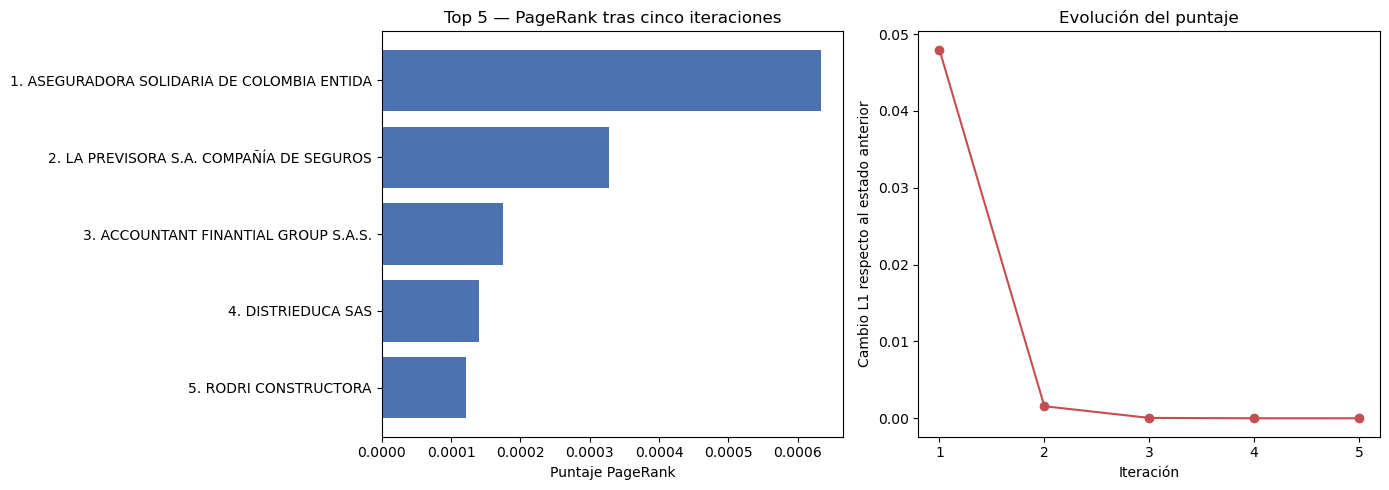

In [4]:
top5_p3 = (ranks_p3.join(nodos_p3, "id").select("id", "tipo", "nombre", "pagerank")
    .orderBy(F.desc("pagerank"), F.asc("id")).limit(5).collect())
spark.createDataFrame(top5_p3).show(5, truncate=False)
spark.createDataFrame(historial_p3, ["iteracion", "segundos", "suma_pagerank", "cambio_L1"]).show(truncate=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
etiquetas_p3 = [f"{i+1}. {r.nombre[:40]}" for i, r in enumerate(top5_p3)]
axes[0].barh(etiquetas_p3[::-1], [r.pagerank for r in top5_p3][::-1], color="#4C72B0")
axes[0].set_title("Top 5 — PageRank tras cinco iteraciones")
axes[0].set_xlabel("Puntaje PageRank")
axes[1].plot([r[0] for r in historial_p3], [r[3] for r in historial_p3], "o-", color="#C44E52")
axes[1].set_xticks(range(1, 6))
axes[1].set_xlabel("Iteración")
axes[1].set_ylabel("Cambio L1 respecto al estado anterior")
axes[1].set_title("Evolución del puntaje")
plt.tight_layout()
plt.show()

### Conclusiones

En esta red las entidades transfieren importancia a sus contratistas. Un contratista recibe más aporte si lo contratan varias entidades y si estas reparten su puntaje entre pocos proveedores. Como se separaron los roles, todos los contratistas carecen de salidas: redistribuir su masa evita perderla en el siguiente paso. La siguiente celda resume automáticamente los resultados medidos.

In [5]:
lider_p3 = top5_p3[0]
display(Markdown(
    f"Se construyó una red con **{numero_nodos_p3:,} nodos** y **{numero_aristas_p3:,} aristas distintas**, "
    f"a partir de {registros_validos_p3:,} registros adjudicados válidos. "
    f"Las cinco iteraciones, incluidos sus controles, tardaron **{tiempo_algoritmo_p3:.2f} s** "
    f"(preparación: {tiempo_preparacion_p3:.2f} s). El mayor puntaje fue el de "
    f"**{lider_p3.nombre}** ({lider_p3.tipo}), con **{lider_p3.pagerank:.8f}**. "
    f"La suma se mantuvo próxima a 1 en los cinco pasos y el cambio L1 final fue **{historial_p3[-1][3]:.8f}**. "
))
for recurso_p3 in [ranks_p3, aristas_p3, nodos_p3, transiciones_p3, sin_salidas_p3]:
    recurso_p3.unpersist()

Se construyó una red con **108,651 nodos** y **255,530 aristas distintas**, a partir de 872,435 registros adjudicados válidos. Las cinco iteraciones, incluidos sus controles, tardaron **58.66 s** (preparación: 48.36 s). El mayor puntaje fue el de **ASEGURADORA SOLIDARIA DE COLOMBIA ENTIDAD COOPERATIVA.** (Contratista), con **0.00063396**. La suma se mantuvo próxima a 1 en los cinco pasos y el cambio L1 final fue **0.00000006**. 